# Project StayWise: data analysis walkthrough
**Group 15 · Domain 15: Hospitality & Tourism (HorizonStay Hotels)**

This notebook reproduces **every number in our pre-submission paper** from the three CSV files we were given,
and explains each result in plain language so the whole team can speak to it.

**Tip:** run the cells **in order from the top**, or use *Kernel > Restart & Run All*. Later sections reuse numbers from earlier ones.

**How to run it.** Keep the three files (`Hospitality_Tourism.csv`, `Hospitality_Tourism_Room_Availability.csv`,
`Hospitality_Tourism_Data_Dictionary.csv`) in a folder called `data`. The notebook finds it automatically, whether `data`
sits next to the notebook or one level above it (for example `project/code/` for the notebook and `project/data/` for the files).
Charts are saved in the `figures` (or `figure`) folder next to `data`. Then *Run all*.
If your folders have other names, set `DATA_DIR` by hand in the first code cell.
It needs only `pandas`, `numpy` and `matplotlib`.

**How each section is laid out**
- **The paper says:** the sentence or number from our document.
- **What the code does:** one line on the method.
- **How to read it:** what to tell the team.


## 1. Setup and load the three files

**The paper says:** we examined 17,661 reservations from 6,216 guests, plus 13,158 daily room-inventory records.

**What the code does:** loads the three files. `R` is a small dictionary where we collect every number we compute,
so section 13 can compare them with the paper.

**How to read it:**
- `Hospitality_Tourism.csv` is the main table: **one row per booking**, 54 columns.
- `Hospitality_Tourism_Room_Availability.csv` has **room counts per hotel, day and room type** (capacity).
- `Hospitality_Tourism_Data_Dictionary.csv` explains each column and **when it becomes known**.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:            # plain Python script
    display = print

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (7.5, 3.6), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
BLUE, GREY = "#2F6EBA", "#9AA5B1"

# --- find the data folder automatically -------------------------------------------------------
# Works for:  project/data + project/code/this_file   (data one level up)
#             project/data + project/this_file         (data next to the file)
# If your folders are named differently, set it by hand, e.g.  DATA_DIR = Path("../my_data_folder")
try:
    HERE = Path(__file__).resolve().parent      # running as a .py script
except NameError:
    HERE = Path.cwd()                           # running inside Jupyter

CSV = "Hospitality_Tourism.csv"
search = [HERE / "data", HERE.parent / "data", HERE.parent.parent / "data", HERE, HERE.parent]
DATA_DIR = next((d for d in search if (d / CSV).exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        f"Could not find {CSV}. Looked in:\n  " + "\n  ".join(str(d) for d in search)
        + "\nPut the three Domain 15 CSV files in a 'data' folder, or set DATA_DIR by hand above.")

# --- charts go to a 'figures' (or 'figure') folder next to the data folder ------------------------
BASE = DATA_DIR.parent if DATA_DIR.name == "data" else DATA_DIR
FIG_DIR = next((BASE / n for n in ("figures", "figure") if (BASE / n).exists()), BASE / "figures")
FIG_DIR.mkdir(exist_ok=True)
print("Reading data from:", DATA_DIR.resolve())
print("Saving charts to :", FIG_DIR.resolve())

bookings = pd.read_csv(DATA_DIR / "Hospitality_Tourism.csv", low_memory=False)
inventory = pd.read_csv(DATA_DIR / "Hospitality_Tourism_Room_Availability.csv")
dictionary = pd.read_csv(DATA_DIR / "Hospitality_Tourism_Data_Dictionary.csv")

R = {}   # every number we compute is stored here, then checked against the paper in section 13
R["bookings"] = len(bookings)
R["inventory_rows"] = len(inventory)

print(f"bookings  : {bookings.shape[0]:,} rows x {bookings.shape[1]} columns")
print(f"inventory : {inventory.shape[0]:,} rows x {inventory.shape[1]} columns")
print(f"dictionary: {dictionary.shape[0]} rows")
display(bookings.head(3).T)

Reading data from: C:\Users\Admin\OneDrive\Downloads\data
Saving charts to : C:\Users\Admin\OneDrive\Downloads\figures
bookings  : 17,661 rows x 54 columns
inventory : 13,158 rows x 6 columns
dictionary: 60 rows


,0,1,2
Booking_ID,BK0000001,BK0000002,BK0000003
Guest_ID,G003722,G006533,G003991
Hotel_ID,H06,H05,H03
Booking_Date,2023-07-24,2023-07-27,2023-07-28
Scheduled_Arrival_Date,2024-01-20,2024-01-23,2024-01-24
Scheduled_Departure_Date,2024-01-27,2024-01-27,2024-01-26
Location_Type,Mixed,Mixed,Leisure
Guest_Segment,Family,Leisure,NaN
Membership_Tier,NaN,NaN,Silver
Booking_Channel,OTA,OTA,OTA


## 2. The data dictionary and the leakage map

**The paper says:** *"12 columns are known only after a stay ends ... so predictions use booking-time fields only."*

**What the code does:** reads the dictionary's `Information_Availability` column and counts how many columns
fall into each group.

**How to read it:**
- **Known at booking:** safe to use when we predict whether a booking will complete.
- **Known only after the stay (12 columns):** these *reveal the answer*. For example `Actual_Nights` is zero for a
  cancelled booking, so a model using it would look brilliant and be useless. This is **data leakage**.
- **Administrative / legacy:** codes with no business meaning, to be ignored.
- Notice that the "after the stay" list includes `Booking_Status` itself: that is the outcome we want to predict, so it is the target, never an input.


In [2]:
avail = dictionary[dictionary["Dataset"] == "Hospitality_Tourism.csv"]
POST = "After cancellation, arrival, stay, or settlement"
ADMIN = "Extraction / administration"

print(avail["Information_Availability"].value_counts().to_string())

post_cols = avail.loc[avail["Information_Availability"] == POST, "Column"].tolist()
admin_cols = avail.loc[avail["Information_Availability"] == ADMIN, "Column"].tolist()
R["post_outcome_cols"] = len(post_cols)

print("\nKnown only AFTER the outcome (never use to predict at booking time):")
print(post_cols)
print("\nAdministrative / legacy columns (ignore):")
print(admin_cols)

Information_Availability
At booking / recorded booking attribute             36
After cancellation, arrival, stay, or settlement    12
Extraction / administration                          6

Known only AFTER the outcome (never use to predict at booking time):
['Booking_Status', 'Cancellation_Date', 'Actual_Nights', 'Occupied_Room_Nights', 'Service_Incidents_Count', 'Complaint_Count', 'Complaint_Response_Min', 'Guest_Satisfaction_Score', 'Realized_Room_Revenue_INR', 'Cancellation_NoShow_Fee_INR', 'Channel_Commission_INR', 'Net_Revenue_After_Channel_Costs_INR']

Administrative / legacy columns (ignore):
['Extract_Version', 'Snapshot_Date', 'Archive_Folder_Number', 'Reservation_Batch_Color', 'Old_Agent_Reference', 'Migration_Remarks']


## 3. Data-quality audit

**The paper says (Section 2):** *membership is 67% blank, text has stray spaces, some columns are duplicated, constant or legacy
codes; 4,154 bookings show negative net revenue; about 35% of completed stays have no satisfaction score.*
The instructor also warned that the data has **intentionally redundant columns**.

**What the code does:** runs each check once and prints the evidence.

**How to read it:**
- **No duplicate rows or repeated booking IDs:** good, each row is a real, separate booking.
- **Stray spaces** such as `'ota '` would make one channel look like two. We fix this in section 4.
- **Blank membership (67%)** may simply mean "no membership", but the data also has explicit `none` labels, so we must
  confirm what blank means before we decide.
- **Duplicate columns** (`Lead_Time_Days` = `Advance_Booking_Days`) carry no new information.
- **Our two formula checks pass on every row:** booked rate = listed rate x (1 - discount), and net revenue = realized + fees
  - commission - acquisition cost. This tells us we understand how the money columns are built.
- **Negative net revenue** looks odd, but the breakdown by booking status explains it: **every one of the 4,154 is a cancelled or no-show booking** that earned nothing yet still carried a small acquisition cost. The negative sign is expected, not an error.

In [3]:
R["dup_rows"] = int(bookings.duplicated().sum())
R["dup_ids"] = int(bookings["Booking_ID"].duplicated().sum())
print(f"duplicate rows: {R['dup_rows']} | repeated Booking_IDs: {R['dup_ids']}")

# stray spaces in text labels
for col in ["Booking_Channel", "Membership_Tier"]:
    s = bookings[col].dropna()
    padded = int((s != s.str.strip()).sum())
    R[f"padded_{col}"] = padded
    print(f"{col}: {padded} values with stray spaces -> {sorted(s[s != s.str.strip()].unique())[:6]}")

# blanks
missing = (bookings.isna().mean() * 100).round(1).sort_values(ascending=False)
print("\nColumns with blanks (% of rows):")
display(missing[missing > 0].to_frame("% blank"))
R["membership_blank_pct"] = bookings["Membership_Tier"].isna().mean() * 100

# constant and duplicated information
constant = [c for c in bookings.columns if bookings[c].nunique(dropna=True) <= 1]
lead_same = bool((bookings["Lead_Time_Days"] == bookings["Advance_Booking_Days"]).all())
hours_same = bool(((bookings["Scheduled_Stay_Hours"] - bookings["Scheduled_Nights"] * 24).abs() < 1e-6).all())
print("\nConstant / empty columns:", constant)
print("Lead_Time_Days == Advance_Booking_Days on every row:", lead_same)
print("Scheduled_Stay_Hours == Scheduled_Nights x 24 on every row:", hours_same)

# do we understand how the money columns are built?
booked_ok = (((bookings["Listed_Room_Rate_INR"] * (1 - bookings["Discount_Pct"] / 100))
              - bookings["Booked_Room_Rate_INR"]).abs() < 1).mean()
net_calc = (bookings["Realized_Room_Revenue_INR"] + bookings["Cancellation_NoShow_Fee_INR"]
            - bookings["Channel_Commission_INR"] - bookings["Acquisition_Cost_INR"])
net_ok = ((net_calc - bookings["Net_Revenue_After_Channel_Costs_INR"]).abs() < 1).mean()
print(f"\nBooked = Listed x (1 - Discount) holds on {booked_ok:.1%} of rows")
print(f"Net = Realized + Fee - Commission - Acquisition holds on {net_ok:.1%} of rows")

# negative net revenue
neg = bookings["Net_Revenue_After_Channel_Costs_INR"] < 0
R["negative_net"] = int(neg.sum())
print(f"\nBookings with negative net revenue: {R['negative_net']:,}")
print(bookings.loc[neg, "Booking_Status"].value_counts().to_string())

# survey coverage among completed stays
done = bookings[bookings["Booking_Status"] == "Completed"]
R["survey_response_pct"] = done["Guest_Satisfaction_Score"].notna().mean() * 100
print(f"\nCompleted stays with a satisfaction score: {R['survey_response_pct']:.1f}% "
      f"(so {100 - R['survey_response_pct']:.1f}% have none)")

duplicate rows: 0 | repeated Booking_IDs: 0
Booking_Channel: 253 values with stray spaces -> ['corporate ', 'direct ', 'ota ', 'travel agent ']
Membership_Tier: 249 values with stray spaces -> ['gold ', 'none ', 'silver ']

Columns with blanks (% of rows):


,% blank
Migration_Remarks,100.0
Old_Agent_Reference,91.7
Complaint_Response_Min,78.3
Cancellation_Date,76.3
Membership_Tier,67.3
Guest_Satisfaction_Score,52.8
Complaint_Count,27.1
Service_Incidents_Count,27.1
Meal_Plan,2.8
Guest_Segment,2.7



Constant / empty columns: ['Hotel_Group', 'Country', 'Currency', 'Extract_Version', 'Snapshot_Date', 'Migration_Remarks']
Lead_Time_Days == Advance_Booking_Days on every row: True
Scheduled_Stay_Hours == Scheduled_Nights x 24 on every row: True

Booked = Listed x (1 - Discount) holds on 100.0% of rows
Net = Realized + Fee - Commission - Acquisition holds on 100.0% of rows

Bookings with negative net revenue: 4,154
Booking_Status
Cancelled    3791
No-show       363

Completed stays with a satisfaction score: 64.8% (so 35.2% have none)


## 4. Clean the data

**What the code does:** fixes the stray spaces in channel and membership labels, shows blank guest segment as
`Unknown`, and creates the helper columns we use below: `non_completed` (cancelled or no-show), `cancelled`, and
simple bands for lead time and discount.

**How to read it:** after this step there are exactly four channels (OTA, Direct, Corporate, Travel Agent), so numbers
by channel add up properly. We keep a separate cleaned table `df` and never overwrite the original `bookings`.

In [4]:
df = bookings.copy()

channel_map = {"ota": "OTA", "direct": "Direct", "corporate": "Corporate", "travel agent": "Travel Agent"}
df["Booking_Channel"] = df["Booking_Channel"].str.strip().str.lower().map(channel_map)
df["Membership_Tier"] = (df["Membership_Tier"].str.strip().str.lower()
                         .map({"silver": "Silver", "gold": "Gold", "none": "None"}).fillna("Blank"))
df["Guest_Segment"] = df["Guest_Segment"].fillna("Unknown")

df["non_completed"] = (df["Booking_Status"] != "Completed").astype(int)   # cancelled + no-show
df["cancelled"] = (df["Booking_Status"] == "Cancelled").astype(int)
df["lead_bucket"] = pd.cut(df["Lead_Time_Days"], [-1, 7, 14, 30, 60, 10**6],
                           labels=["0-7", "8-14", "15-30", "31-60", "61+"])
df["discount_bucket"] = pd.cut(df["Discount_Pct"], [-1, 0, 10, 15, 100],
                               labels=["0%", "1-10%", "11-15%", "16%+"])

assert df["Booking_Channel"].notna().all(), "unexpected channel label"
print(df["Booking_Channel"].value_counts().to_string())

Booking_Channel
OTA             7971
Direct          4967
Corporate       2963
Travel Agent    1760


## 5. The business at a glance

**The paper says:** *HorizonStay runs six hotels in India (two business, two leisure, two mixed; 22 rooms each) ...
17,661 reservations (2024-2025) from 6,216 guests.*

**What the code does:** summarises hotels, room counts, guests and date ranges.

**How to read it:** the six hotels are small and similar in size, so differences between them are not just about size.
Bookings were made from mid-2023, and stays run from January 2024 to December 2025.

In [5]:
hotels = df.groupby("Hotel_ID")["Location_Type"].first()
first_day = inventory["Stay_Date"].min()
rooms = inventory[inventory["Stay_Date"] == first_day].groupby("Hotel_ID")["Physical_Rooms"].sum()
overview = pd.DataFrame({"location_type": hotels, "rooms": rooms, "bookings": df.groupby("Hotel_ID").size()})
display(overview)

R["hotels"] = df["Hotel_ID"].nunique()
R["rooms_min"], R["rooms_max"] = int(rooms.min()), int(rooms.max())
R["guests"] = df["Guest_ID"].nunique()
print(f"\nHotels: {R['hotels']} | rooms per hotel: {R['rooms_min']}-{R['rooms_max']} | unique guests: {R['guests']:,}")
print(f"Bookings made : {df['Booking_Date'].min()} to {df['Booking_Date'].max()}")
print(f"Arrivals      : {df['Scheduled_Arrival_Date'].min()} to {df['Scheduled_Arrival_Date'].max()}")
print(f"Data snapshot : {df['Snapshot_Date'].unique()[0]}")

,location_type,rooms,bookings
Hotel_ID,,,
H01,Business,22,2936
H02,Business,22,2917
H03,Leisure,22,2948
H04,Leisure,22,2905
H05,Mixed,22,2935
H06,Mixed,22,3020



Hotels: 6 | rooms per hotel: 22-22 | unique guests: 6,216
Bookings made : 2023-07-24 to 2025-12-21
Arrivals      : 2024-01-01 to 2025-12-24
Data snapshot : 2026-01-01


## 6. How many bookings never complete?

**The paper says:** *27.1% of bookings never complete (23.7% cancelled, 3.4% no-show).*

**What the code does:** counts each booking outcome. We call cancelled + no-show **non-completion**: the booking
was made but the stay never happened.

**How to read it:** more than one booking in four falls through. A cancelled room that is not resold, and a no-show that
blocks a room, are both lost revenue. This is our **primary objective**: predict, at booking time, which bookings are at risk.

,bookings,share_%
Booking_Status,,
Completed,12869,72.9
Cancelled,4194,23.7
No-show,598,3.4


Non-completion: 27.1% (cancelled 23.7% + no-show 3.4%)


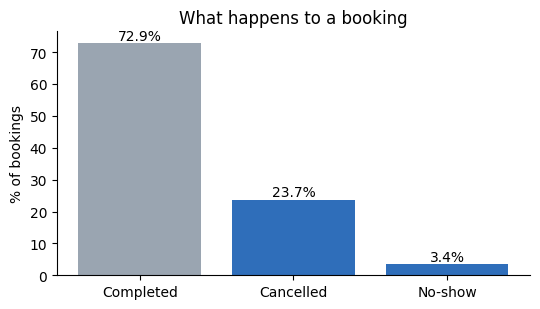

In [6]:
status = df["Booking_Status"].value_counts()
display(pd.DataFrame({"bookings": status, "share_%": (status / len(df) * 100).round(1)}))

R["noncomp_pct"] = df["non_completed"].mean() * 100
R["cancelled_pct"] = df["cancelled"].mean() * 100
R["noshow_pct"] = (df["Booking_Status"] == "No-show").mean() * 100
print(f"Non-completion: {R['noncomp_pct']:.1f}% (cancelled {R['cancelled_pct']:.1f}% + no-show {R['noshow_pct']:.1f}%)")

fig, ax = plt.subplots(figsize=(5.5, 3.2))
order = ["Completed", "Cancelled", "No-show"]
vals = [status[k] / len(df) * 100 for k in order]
ax.bar(order, vals, color=[GREY, BLUE, BLUE])
for i, v in enumerate(vals):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_ylabel("% of bookings")
ax.set_title("What happens to a booking")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_outcomes.png", dpi=150); plt.show()

## 7. When do cancellations arrive?

**The paper says:** *a third of cancellations come within 7 days of arrival, leaving little time to resell the room.*

**What the code does:** for each cancelled booking, counts the days between the cancellation date and the arrival date.

**How to read it:** the later a cancellation arrives, the harder it is to resell the room. So a model that flags
risky bookings **early** is worth more than one that only confirms a cancellation after the fact.

Cancelled bookings: 4,194
Cancelled within 7 days of arrival: 32.7%
Median cancellation time: 13 days before arrival


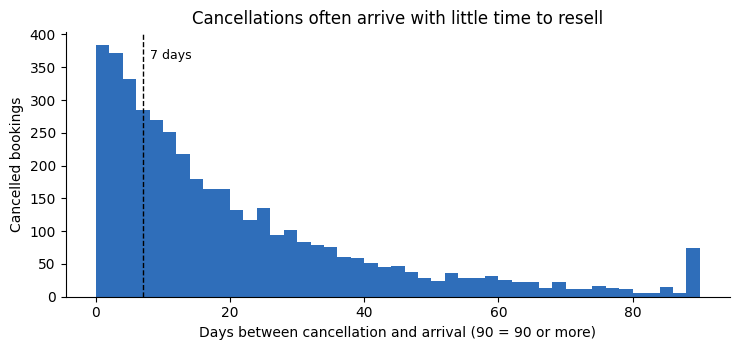

In [7]:
canc = df[df["Booking_Status"] == "Cancelled"].copy()
canc["days_before_arrival"] = (pd.to_datetime(canc["Scheduled_Arrival_Date"])
                               - pd.to_datetime(canc["Cancellation_Date"])).dt.days

R["canc_within7_pct"] = (canc["days_before_arrival"] <= 7).mean() * 100
R["canc_median_days"] = float(canc["days_before_arrival"].median())
print(f"Cancelled bookings: {len(canc):,}")
print(f"Cancelled within 7 days of arrival: {R['canc_within7_pct']:.1f}%")
print(f"Median cancellation time: {R['canc_median_days']:.0f} days before arrival")

fig, ax = plt.subplots()
ax.hist(canc["days_before_arrival"].clip(upper=90), bins=range(0, 92, 2), color=BLUE)
ax.axvline(7, color="black", ls="--", lw=1)
ax.text(8, ax.get_ylim()[1] * 0.9, "7 days", fontsize=9)
ax.set_xlabel("Days between cancellation and arrival (90 = 90 or more)")
ax.set_ylabel("Cancelled bookings")
ax.set_title("Cancellations often arrive with little time to resell")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_cancellation_timing.png", dpi=150); plt.show()

## 8. Who is most likely not to complete?

**The paper says:** *non-completion is 35% for OTA vs 20-22% for other channels, 44% for lead times over 60 days vs about
20% within 14 days, and 33% without a deposit vs 14% for non-refundable bookings. Cancellations stay near 24% at every
discount level.*

**What the code does:** for each factor, groups the bookings and shows the share that did not complete.

**How to read it:**
- **Channel:** OTA bookings fall through far more often than the other channels.
- **Lead time:** the further ahead someone books, the more likely they are to drop out.
- **Deposit:** a deposit (especially non-refundable) strongly protects the booking.
- **Discount:** the rate is flat across discount levels, so **discounting does not obviously explain cancellations**.

These are raw rates, not proof of cause: channel, lead time and deposit may all overlap. That is why we need a model
later to separate them.

By channel


,bookings,non_completed,cancelled,non_completion_%,cancelled_%
Booking_Channel,,,,,
OTA,7971,2806,2529,35.2,31.7
Direct,4967,996,821,20.1,16.5
Corporate,2963,608,522,20.5,17.6
Travel Agent,1760,382,322,21.7,18.3


By lead time (days)


,bookings,non_completed,cancelled,non_completion_%,cancelled_%
lead_bucket,,,,,
0-7,1733,349,274,20.1,15.8
8-14,2810,565,481,20.1,17.1
15-30,5796,1334,1146,23.0,19.8
31-60,5036,1538,1348,30.5,26.8
61+,2286,1006,945,44.0,41.3


By deposit type


,bookings,non_completed,cancelled,non_completion_%,cancelled_%
Deposit_Type,,,,,
No Deposit,8857,2962,2599,33.4,29.3
Refundable,5206,1318,1192,25.3,22.9
Non-refundable,3598,512,403,14.2,11.2


By discount given


,bookings,non_completed,cancelled,non_completion_%,cancelled_%
discount_bucket,,,,,
0%,4422,1214,1057,27.5,23.9
1-10%,7107,1904,1664,26.8,23.4
11-15%,3123,866,760,27.7,24.3
16%+,3009,808,713,26.9,23.7


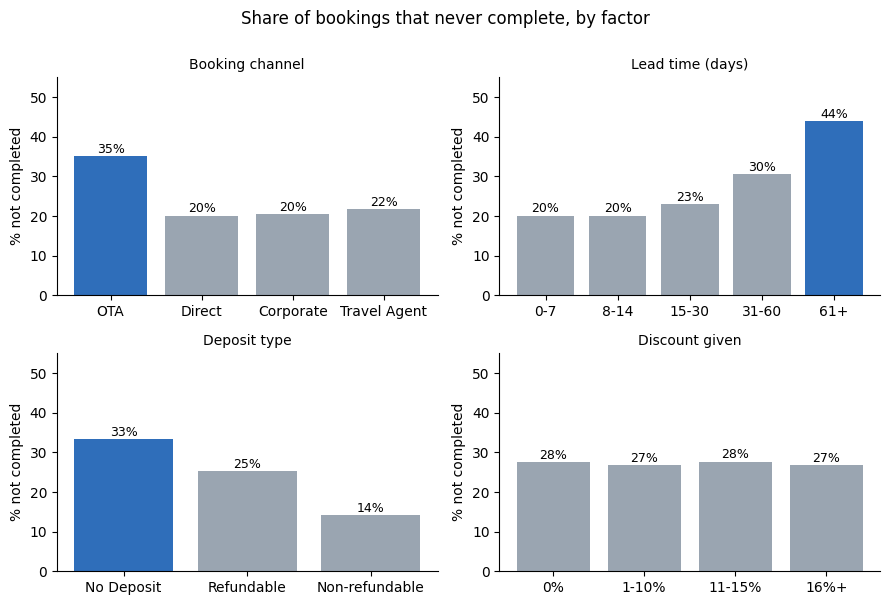

In [8]:
def risk_table(col):
    t = df.groupby(col, observed=True).agg(bookings=("non_completed", "size"),
                                           non_completed=("non_completed", "sum"),
                                           cancelled=("cancelled", "sum"))
    t["non_completion_%"] = (t["non_completed"] / t["bookings"] * 100).round(1)
    t["cancelled_%"] = (t["cancelled"] / t["bookings"] * 100).round(1)
    return t

by_channel = risk_table("Booking_Channel").loc[["OTA", "Direct", "Corporate", "Travel Agent"]]
by_lead = risk_table("lead_bucket")
by_deposit = risk_table("Deposit_Type").loc[["No Deposit", "Refundable", "Non-refundable"]]
by_discount = risk_table("discount_bucket")

for name, t in [("By channel", by_channel), ("By lead time (days)", by_lead),
                ("By deposit type", by_deposit), ("By discount given", by_discount)]:
    print(name)
    display(t)

R["ota_noncomp"] = by_channel.loc["OTA", "non_completion_%"]
R["other_noncomp_min"] = by_channel.drop("OTA")["non_completion_%"].min()
R["other_noncomp_max"] = by_channel.drop("OTA")["non_completion_%"].max()
R["lead61_noncomp"] = by_lead.loc["61+", "non_completion_%"]
R["lead_le14_noncomp"] = df.loc[df["Lead_Time_Days"] <= 14, "non_completed"].mean() * 100
R["nodeposit_noncomp"] = by_deposit.loc["No Deposit", "non_completion_%"]
R["nonrefund_noncomp"] = by_deposit.loc["Non-refundable", "non_completion_%"]
R["discount_cancel_min"] = by_discount["cancelled_%"].min()
R["discount_cancel_max"] = by_discount["cancelled_%"].max()

fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, (t, title) in zip(axes.ravel(), [(by_channel, "Booking channel"), (by_lead, "Lead time (days)"),
                                         (by_deposit, "Deposit type"), (by_discount, "Discount given")]):
    vals = t["non_completion_%"]
    spread = vals.max() - vals.min()                      # highlight only when the differences are real
    colors = [BLUE if (spread > 5 and v == vals.max()) else GREY for v in vals]
    ax.bar([str(i) for i in t.index], vals, color=colors)
    for i, v in enumerate(vals):
        ax.text(i, v + 0.8, f"{v:.0f}%", ha="center", fontsize=9)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, 55)
    ax.set_ylabel("% not completed")
plt.suptitle("Share of bookings that never complete, by factor", y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_risk_factors.png", dpi=150); plt.show()

## 9. Where does the money go?

**The paper says:** *₹305M was booked but only ₹218.7M realized (₹9.6M recovered through fees). OTA brings 45% of bookings
at 18% commission: ₹9.8k net per booking vs ₹13.8k for Direct.* And in Section 5: *about ₹86M went unrealized; recovering
even 5% (₹4.3M) far exceeds the project's cash cost.*

**What the code does:** adds up booked value, realized revenue, fees, commission and net revenue, overall and by channel.

**How to read it:**
- **Booked** is what guests reserved. **Realized** is what the hotels actually earned from stays. The gap is the
  revenue lost to cancellations and no-shows. Fees recover only a small part of it.
- **Net revenue** is after commission and acquisition cost. **It is not profit** (the data has no operating costs).
- OTA brings the most bookings but the least net money per booking: high volume, high commission, high cancellations.
- The 5% figure is an **illustration of scale**, not a forecast.

,INR million
Booked_Value_INR,305.0
Realized_Room_Revenue_INR,218.7
Cancellation_NoShow_Fee_INR,9.6
Channel_Commission_INR,22.6
Acquisition_Cost_INR,1.7
Net_Revenue_After_Channel_Costs_INR,204.0


Booked but never realized: INR 86.3M; fees recovered INR 9.6M; 5% of the gap = INR 4.3M


,bookings,booked,realized,net,commission_pct,share_of_bookings_%,net_per_booking
Booking_Channel,,,,,,,
OTA,7971,142165032.7,90365628.0,78414349.5,18.0,45.1,9837.0
Direct,4967,85684759.6,67512910.0,68643510.4,0.0,28.1,13820.0
Corporate,2963,45434381.3,36135247.5,34812058.0,6.0,16.8,11749.0
Travel Agent,1760,31700957.5,24693454.6,22148359.0,12.0,10.0,12584.0


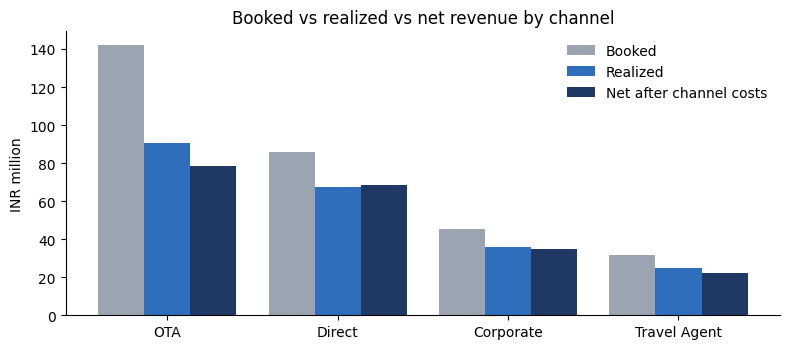

In [9]:
money_cols = ["Booked_Value_INR", "Realized_Room_Revenue_INR", "Cancellation_NoShow_Fee_INR",
              "Channel_Commission_INR", "Acquisition_Cost_INR", "Net_Revenue_After_Channel_Costs_INR"]
tot = df[money_cols].sum()
display((tot / 1e6).round(1).to_frame("INR million"))

R["booked_m"] = tot["Booked_Value_INR"] / 1e6
R["realized_m"] = tot["Realized_Room_Revenue_INR"] / 1e6
R["fees_m"] = tot["Cancellation_NoShow_Fee_INR"] / 1e6
R["net_m"] = tot["Net_Revenue_After_Channel_Costs_INR"] / 1e6
R["gap_m"] = R["booked_m"] - R["realized_m"]
R["five_pct_m"] = R["gap_m"] * 0.05
print(f"Booked but never realized: INR {R['gap_m']:.1f}M; fees recovered INR {R['fees_m']:.1f}M; "
      f"5% of the gap = INR {R['five_pct_m']:.1f}M")

by_ch = df.groupby("Booking_Channel").agg(
    bookings=("Booking_ID", "size"),
    booked=("Booked_Value_INR", "sum"),
    realized=("Realized_Room_Revenue_INR", "sum"),
    net=("Net_Revenue_After_Channel_Costs_INR", "sum"),
    commission_pct=("Channel_Commission_Pct", "mean"),
).loc[["OTA", "Direct", "Corporate", "Travel Agent"]]
by_ch["share_of_bookings_%"] = (by_ch["bookings"] / by_ch["bookings"].sum() * 100).round(1)
by_ch["net_per_booking"] = (by_ch["net"] / by_ch["bookings"]).round(0)
display(by_ch.round(1))

R["ota_share_pct"] = by_ch.loc["OTA", "share_of_bookings_%"]
R["ota_commission_pct"] = by_ch.loc["OTA", "commission_pct"]
R["ota_net_per_booking_k"] = by_ch.loc["OTA", "net_per_booking"] / 1000
R["direct_net_per_booking_k"] = by_ch.loc["Direct", "net_per_booking"] / 1000

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(by_ch)); w = 0.27
ax.bar(x - w, by_ch["booked"] / 1e6, w, label="Booked", color=GREY)
ax.bar(x, by_ch["realized"] / 1e6, w, label="Realized", color=BLUE)
ax.bar(x + w, by_ch["net"] / 1e6, w, label="Net after channel costs", color="#1F3864")
ax.set_xticks(x); ax.set_xticklabels(by_ch.index)
ax.set_ylabel("INR million"); ax.set_title("Booked vs realized vs net revenue by channel"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "04_revenue_by_channel.png", dpi=150); plt.show()

## 10. Occupancy

**The paper says:** *room occupancy is about 40%.*

**What the code does:** occupancy = **occupied room-nights divided by available room-nights**. Occupied nights come from
the bookings file, available nights from the inventory file. This is the one place where we use the second file.

**How to read it:** roughly four rooms in ten are filled on an average night. That is why every cancelled booking matters:
there is spare capacity to sell, but only if the hotel knows early that a room is coming back.

Occupied room-nights : 38,499
Available room-nights: 96,312
Occupancy            : 40.0%


,occupied_room_nights,available_room_nights,occupancy_%
Hotel_ID,,,
H01,6504,16052,40.5
H02,6402,16052,39.9
H03,6495,16052,40.5
H04,6298,16052,39.2
H05,6224,16052,38.8
H06,6576,16052,41.0


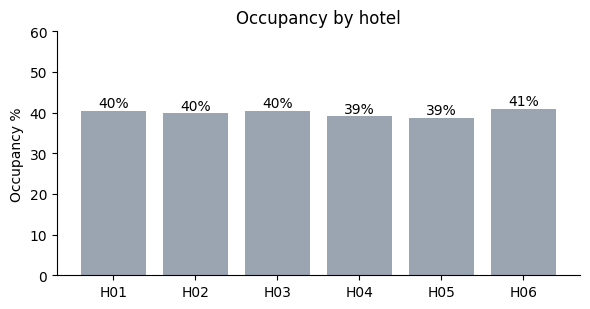

In [10]:
occupied = df["Occupied_Room_Nights"].sum()
available = inventory["Available_Rooms"].sum()
R["occupancy_pct"] = occupied / available * 100
print(f"Occupied room-nights : {occupied:,.0f}")
print(f"Available room-nights: {available:,.0f}")
print(f"Occupancy            : {R['occupancy_pct']:.1f}%")

by_hotel = pd.DataFrame({"occupied_room_nights": df.groupby("Hotel_ID")["Occupied_Room_Nights"].sum(),
                         "available_room_nights": inventory.groupby("Hotel_ID")["Available_Rooms"].sum()})
by_hotel["occupancy_%"] = (by_hotel["occupied_room_nights"] / by_hotel["available_room_nights"] * 100).round(1)
display(by_hotel)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(by_hotel.index, by_hotel["occupancy_%"], color=GREY)
for i, v in enumerate(by_hotel["occupancy_%"]):
    ax.text(i, v + 0.8, f"{v:.0f}%", ha="center")
ax.set_ylabel("Occupancy %"); ax.set_title("Occupancy by hotel"); ax.set_ylim(0, 60)
plt.tight_layout(); plt.savefig(FIG_DIR / "05_occupancy.png", dpi=150); plt.show()

## 11. Guests, retention and satisfaction

**The paper says:** *62.5% of guests book more than once; satisfaction varies by hotel (7.7 at H04 vs 8.3 at H03), but
only 65% of completed stays leave a score.* And: *repeat behaviour is cut off at the 1 Jan 2026 snapshot.*

**What the code does:** counts bookings per guest, averages satisfaction by hotel (completed stays only, because only
they can leave a score), and shows the snapshot date.

**How to read it:**
- Most guests come back, so **retention can be studied** (our stretch objective).
- H04 has the lowest satisfaction, so something about that hotel is worth investigating.
- A third of completed stays have no score, so satisfaction may be **biased towards guests who bothered to answer**.
- Guests who booked near the end of the data have had little time to come back. A guest who has not returned *yet*
  is not the same as a guest who never will.

Guests: 6,216 | with 2+ bookings: 62.5%


,guests
bookings (6 = 6 or more),
1,2329
2,1330
3,887
4,542
5,390
6,738


,avg satisfaction
Hotel_ID,
H01,8.06
H02,7.82
H03,8.25
H04,7.66
H05,7.95
H06,8.18



Latest arrival in the data: 2025-12-24 | snapshot date: 2026-01-01


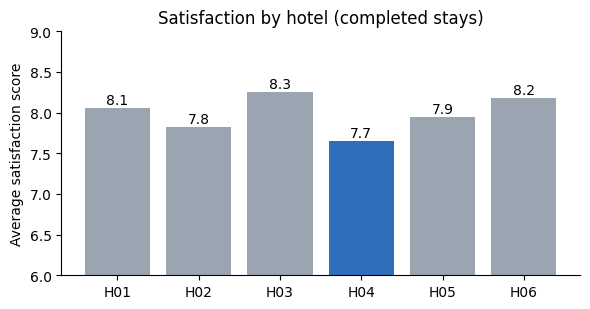

In [11]:
per_guest = df.groupby("Guest_ID").size()
R["repeat_pct"] = (per_guest >= 2).mean() * 100
print(f"Guests: {len(per_guest):,} | with 2+ bookings: {R['repeat_pct']:.1f}%")
display(per_guest.clip(upper=6).value_counts().sort_index().to_frame("guests").rename_axis("bookings (6 = 6 or more)"))

comp = df[df["Booking_Status"] == "Completed"]
sat = comp.groupby("Hotel_ID")["Guest_Satisfaction_Score"].mean()      # keep full precision for the checks
display(sat.round(2).to_frame("avg satisfaction"))
R["sat_h04"], R["sat_h03"] = sat["H04"], sat["H03"]

print(f"\nLatest arrival in the data: {df['Scheduled_Arrival_Date'].max()} | snapshot date: {df['Snapshot_Date'].unique()[0]}")

fig, ax = plt.subplots(figsize=(6, 3.2))
colors = [BLUE if h == sat.idxmin() else GREY for h in sat.index]
ax.bar(sat.index, sat.values, color=colors)
for i, v in enumerate(sat.values):
    ax.text(i, v + 0.05, f"{v:.1f}", ha="center")
ax.set_ylim(6, 9); ax.set_ylabel("Average satisfaction score"); ax.set_title("Satisfaction by hotel (completed stays)")
plt.tight_layout(); plt.savefig(FIG_DIR / "06_satisfaction.png", dpi=150); plt.show()

## 12. The costs section

**The paper says (Section 5):** *192 h (4 members x 6 h/week x 8 weeks) + 10% buffer, about 211 h; about ₹84,000 if valued
at an assumed ₹400/hour; all software, compute and data cost ₹0.*

**What the code does:** the simple arithmetic behind that table.

**How to read it:** the hours per week and the hourly rate are **planning assumptions**, not facts from the data, and the
paper says so. The only real cash cost is zero, because everything is open source and the data is provided.

In [12]:
members, hours_per_week, weeks = 4, 6, 8
effort = members * hours_per_week * weeks      # 192
buffered = effort * 1.10                       # about 211
rate = 400                                     # assumed INR per hour
R["effort_h"], R["buffered_h"], R["effort_value_k"] = effort, round(buffered), buffered * rate / 1000
print(f"Effort: {effort} h; with 10% buffer: {buffered:.0f} h; valued at INR {rate}/h: INR {buffered * rate:,.0f}")

Effort: 192 h; with 10% buffer: 211 h; valued at INR 400/h: INR 84,480


## 13. Does the paper match the data?

**What the code does:** compares each claim in our paper with the number computed above and marks it `OK` or `CHECK`.

**How to read it:** if everything says `OK`, the paper is a faithful summary of the data and every team member can
point to the cell that produced each number. If something says `CHECK`, fix the paper or the code before submitting.

In [13]:
# (label, value in the paper, key in R, tolerance, unit, section that computes it)
CLAIMS = [
    ("Reservations analysed", 17661, "bookings", 0, "", 1),
    ("Room-inventory rows", 13158, "inventory_rows", 0, "", 1),
    ("Columns known only after the outcome", 12, "post_outcome_cols", 0, "", 2),
    ("Membership blank", 67, "membership_blank_pct", 1, "%", 3),
    ("Bookings with negative net revenue", 4154, "negative_net", 0, "", 3),
    ("Completed stays with a score", 65, "survey_response_pct", 1, "%", 3),
    ("Hotels", 6, "hotels", 0, "", 5),
    ("Rooms per hotel", 22, "rooms_max", 0, "", 5),
    ("Unique guests", 6216, "guests", 0, "", 5),
    ("Non-completion rate", 27.1, "noncomp_pct", 0.1, "%", 6),
    ("Cancelled", 23.7, "cancelled_pct", 0.1, "%", 6),
    ("No-show", 3.4, "noshow_pct", 0.1, "%", 6),
    ("Cancellations within 7 days of arrival", 33, "canc_within7_pct", 1, "%", 7),
    ("Median cancellation, days before arrival", 13, "canc_median_days", 0.5, "", 7),
    ("OTA non-completion", 35, "ota_noncomp", 0.5, "%", 8),
    ("Lead time over 60 days", 44, "lead61_noncomp", 0.5, "%", 8),
    ("Lead time within 14 days", 20, "lead_le14_noncomp", 1, "%", 8),
    ("No deposit", 33, "nodeposit_noncomp", 1, "%", 8),
    ("Non-refundable deposit", 14, "nonrefund_noncomp", 1, "%", 8),
    ("Booked value (INR M)", 305, "booked_m", 0.5, "", 9),
    ("Realized revenue (INR M)", 218.7, "realized_m", 0.1, "", 9),
    ("Fees recovered (INR M)", 9.6, "fees_m", 0.1, "", 9),
    ("Net revenue (INR M)", 204, "net_m", 0.5, "", 9),
    ("Booked but unrealized (INR M)", 86, "gap_m", 0.5, "", 9),
    ("5% of the gap (INR M)", 4.3, "five_pct_m", 0.1, "", 9),
    ("OTA share of bookings", 45, "ota_share_pct", 1, "%", 9),
    ("OTA commission", 18, "ota_commission_pct", 0.5, "%", 9),
    ("OTA net per booking (INR k)", 9.8, "ota_net_per_booking_k", 0.1, "", 9),
    ("Direct net per booking (INR k)", 13.8, "direct_net_per_booking_k", 0.1, "", 9),
    ("Occupancy", 40, "occupancy_pct", 1, "%", 10),
    ("Guests who book more than once", 62.5, "repeat_pct", 0.1, "%", 11),
    ("Satisfaction at H04", 7.7, "sat_h04", 0.05, "", 11),
    ("Satisfaction at H03", 8.3, "sat_h03", 0.05, "", 11),
    ("Effort (hours)", 192, "effort_h", 0, "", 12),
    ("Effort with buffer (hours)", 211, "buffered_h", 0.5, "", 12),
    ("Effort value (INR thousand)", 84, "effort_value_k", 0.5, "", 12),
]
# claims about a range of values: (label, paper text, lowest allowed, highest allowed, key of low, key of high, section)
RANGES = [
    ("Other channels non-completion", "20-22%", 19.5, 22.5, "other_noncomp_min", "other_noncomp_max", 8),
    ("Cancellation rate at every discount level", "near 24%", 22.5, 25.5, "discount_cancel_min", "discount_cancel_max", 8),
]

rows, not_run = [], set()
for label, paper, key, tol, unit, section in CLAIMS:
    if key not in R:
        not_run.add(section)
        rows.append((label, f"{paper:,}{unit}", "not computed yet", f"RUN SECTION {section}"))
        continue
    got = R[key]
    rows.append((label, f"{paper:,}{unit}", f"{got:,.1f}{unit}", "OK" if abs(got - paper) <= tol else "CHECK"))
for label, text, lo, hi, k_lo, k_hi, section in RANGES:
    if k_lo not in R or k_hi not in R:
        not_run.add(section)
        rows.append((label, text, "not computed yet", f"RUN SECTION {section}"))
        continue
    rows.append((label, text, f"{R[k_lo]:.1f}-{R[k_hi]:.1f}%", "OK" if (R[k_lo] >= lo and R[k_hi] <= hi) else "CHECK"))

check = pd.DataFrame(rows, columns=["Paper says", "Paper value", "Computed from data", "Match?"])
display(check)

n_ok = int((check["Match?"] == "OK").sum())
print(f"\n{n_ok} of {len(check)} claims in the paper match the data.")
if not_run:
    print("Some numbers are missing because these sections were not run yet (or showed an error): "
          + ", ".join(str(n) for n in sorted(not_run))
          + ".\nScroll up and run those cells, or use Kernel > Restart & Run All, then run this cell again.")

,Paper says,Paper value,Computed from data,Match?
0,Reservations analysed,"17,661","17,661.0",OK
1,Room-inventory rows,"13,158","13,158.0",OK
2,Columns known only after the outcome,12,12.0,OK
3,Membership blank,67%,67.3%,OK
4,Bookings with negative net revenue,"4,154","4,154.0",OK
5,Completed stays with a score,65%,64.8%,OK
6,Hotels,6,6.0,OK
7,Rooms per hotel,22,22.0,OK
8,Unique guests,"6,216","6,216.0",OK
9,Non-completion rate,27.1%,27.1%,OK



38 of 38 claims in the paper match the data.


## 14. What this means for the next steps

Everything above is **description**, which is what the proposal needs. We have deliberately **not trained a model yet**.

| Finding | What it tells us to do next |
|---|---|
| 27% of bookings never complete, and risk is concentrated (OTA, long lead time, no deposit) | **Primary objective:** predict this at booking time, using only the booking-time columns from section 2 |
| ₹86M booked but unrealized; OTA earns the least per booking | **Secondary objective:** compare channels and hotels on net revenue and estimate the value of a booking given its risk |
| 62.5% of guests rebook; satisfaction differs by hotel; 35% of scores are missing | **Stretch objective:** study repeat booking and satisfaction, carefully, because of the missing scores |
| Discounts show no obvious link to cancellations | Test this properly in the model instead of assuming it |
| Everything is a raw association | Never claim "causes"; say "is associated with" |

**Limits to say out loud:** six hotels over two years; net revenue is not profit; membership blanks are unexplained; the
cancellation, deposit and channel patterns overlap, so a model is needed to untangle them.